# 03_Binding_pocket_replacement

In [10]:
import pandas as pd
import numpy as np
import os
import yaml
from collections import Counter
from pymsaviz import MsaViz

import sys
sys.path.append('../src/TAS2Rs_cofolding_utils/')
from complex_utils import get_ligands_interactions, get_binding_site_residues
from other import human_TAS2Rs, read_json
human_TAS2Rs = [f'h{receptor}' for receptor in human_TAS2Rs]
from receptor_region import classify_hTAS2R_residue_region, ReceptorRegionClassyfier
from BW_numbers import TAS2Rs_BW_numbers
from msa import TAS2Rs_MSA

import seaborn as sns
import matplotlib.patches as mpatches
palette = sns.color_palette('Set1')

### Load cryo-EM complexes

In [3]:
# load ReceptorRegionClassyfier
path_to_msa = '../data/sequences/TAS2Rs T-Coffee aligned.fa'
path_to_regions = '../data/sequences/TAS2Rs_known_regions.xlsx'
region_classyfier = ReceptorRegionClassyfier(path_to_regions, path_to_msa)

# load TAS2Rs_BW_numbers
path_to_BW_numbers = '../data/hTAS2Rs_BW_numbers.xlsx'
BW_numbers = TAS2Rs_BW_numbers(path_to_BW_numbers)

In [4]:
# Load metadata on TAS2R cryo-EM complexes
path_to_meta_file = '../data/TAS2R_cryoEM_compexes/TAS2R_cryoEM_complexes_meta.xlsx'
TAS2R_cryoEM_complexes_meta = pd.read_excel(path_to_meta_file)
# Obtain the PDB codes for the published TAS2R cryo-EM complexes
published_TAS2R_cryoEM_pdb_codes = set(TAS2R_cryoEM_complexes_meta['PDB code'].dropna())

In [4]:
# Load TAS2R cryo-EM complexes with one ligand per complex
TAS2R_cryoEM_complexes = []
path_to_TAS2R_cryoEM_complexes_dir = '../data/TAS2R_cryoEM_compexes/one_ligand_per_complex/'
pdb_files = [file for file in os.listdir(path_to_TAS2R_cryoEM_complexes_dir) if file.endswith('.pdb')]

for pdb_file in pdb_files:

    ligand, receptor, Galpha, pdb_code = pdb_file.rstrip('.pdb').split('-')
    ligand = ligand.replace('_', ' ')
    if '(' in ligand:
        ligand = ligand[:-3]

    if not pdb_code in published_TAS2R_cryoEM_pdb_codes:
        continue

    path_to_file = os.path.join(path_to_TAS2R_cryoEM_complexes_dir, pdb_file)

    interactions = get_ligands_interactions(path_to_file)
    interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(f'h{receptor}', residue))
    binding_site = interactions['Region'].value_counts().idxmax()

    TAS2R_cryoEM_complexes.append([path_to_file, pdb_file, ligand, receptor, Galpha, pdb_code, interactions, binding_site])

TAS2R_cryoEM_complexes_df = pd.DataFrame(TAS2R_cryoEM_complexes, columns=['path to file', 'file name', 'ligand', 'receptor', 'Gα', 'PDB code', 'interactions', 'binding site'])
print(f'Number of cryo-EM complexes: {len(TAS2R_cryoEM_complexes_df['PDB code'].unique())}')

Number of cryo-EM complexes: 27


### Get binding site residues

In [5]:
TAS2R_cryoEM_complexes_df['binding site residues'] = TAS2R_cryoEM_complexes_df['path to file'].apply(get_binding_site_residues)

In [6]:
TAS2R_binding_site_residues = []
for (receptor, binding_site), sub_df in TAS2R_cryoEM_complexes_df.groupby(by=['receptor', 'binding site']):
    binding_site_residues = []
    for residues in sub_df['binding site residues'].values:
        binding_site_residues.extend(residues)
    residues_count = pd.DataFrame(Counter(binding_site_residues).items(), columns=['residue', 'count'])
    residues_count['residue number'] = residues_count['residue'].str[1:].astype(int)
    residues_count.sort_values(by='residue number', inplace=True)
    binding_site_residues = residues_count[residues_count['count'] >= len(sub_df) / 2]['residue'].values
    TAS2R_binding_site_residues.append([receptor, binding_site, binding_site_residues, len(binding_site_residues)])
    
TAS2R_binding_site_residues = pd.DataFrame(TAS2R_binding_site_residues, columns=['receptor', 'binding site', 'binding site residues', 'number of binding site residues'])

In [7]:
TAS2R_binding_site_residues

,receptor,binding site,binding site residues,number of binding site residues
0,TAS2R14,extracellular,"[L58, L61, I62, S65, W66, S69, F76, M81, F82, ...",43
1,TAS2R14,intracellular,"[R55, A100, T101, L103, G104, T105, Y107, F108...",34
2,TAS2R16,extracellular,"[Y14, L59, A62, S63, M64, N66, N67, L81, T82, ...",30
3,TAS2R4,extracellular,"[Y6, S13, N17, F62, N65, T66, Y68, F69, V70, N...",30
4,TAS2R43,extracellular,"[L58, V61, L62, L64, N65, W66, R81, T83, A84, ...",33
5,TAS2R46,extracellular,"[L58, V61, L62, N65, W66, T69, R81, A84, Y85, ...",27


### Get binding site residues for hTAS2Rs

In [8]:
msa = TAS2Rs_MSA(path_to_msa)

In [9]:
tas2r14_ecbs_residues = TAS2R_binding_site_residues[(TAS2R_binding_site_residues['receptor'] == 'TAS2R14') & (TAS2R_binding_site_residues['binding site'] == 'extracellular')].iloc[0]['binding site residues']
tas2r14_ecbs_msa_positions = [msa.residue_to_msa_position(residue, 'hTAS2R14') for residue in tas2r14_ecbs_residues]
tas2r14_icbs_residues = TAS2R_binding_site_residues[(TAS2R_binding_site_residues['receptor'] == 'TAS2R14') & (TAS2R_binding_site_residues['binding site'] == 'intracellular')].iloc[0]['binding site residues']
tas2r14_icbs_msa_positions = [msa.residue_to_msa_position(residue, 'hTAS2R14') for residue in tas2r14_icbs_residues]

In [10]:
TAS2Rs_bs_residues = []
binding_sites = ['extracellular', 'intracellular']

for receptor in human_TAS2Rs:
    for binding_site in binding_sites:
        
        if binding_site == 'extracellular':
            msa_positions = tas2r14_ecbs_msa_positions
        elif binding_site == 'intracellular':
            msa_positions = tas2r14_icbs_msa_positions
        else:
            raise ValueError

        receptor_bs_residues = []
        for msa_position in msa_positions:
            
            try:
                residue = msa.msa_position_to_residue(msa_position, receptor)
                receptor_bs_residues.append(residue)
            except:
                continue
        TAS2Rs_bs_residues.append([receptor, binding_site, receptor_bs_residues, len(receptor_bs_residues)])
TAS2Rs_bs_residues = pd.DataFrame(TAS2Rs_bs_residues, columns=['receptor', 'binding site', 'binding site residues', 'number of binding site residues'])

In [11]:
TAS2Rs_bs_residues

,receptor,binding site,binding site residues,number of binding site residues
0,hTAS2R1,extracellular,"[L58, F61, I62, V65, N66, V69, M77, C78, S79, ...",41
1,hTAS2R1,intracellular,"[R55, A96, T97, L99, G100, V101, Y103, C104, V...",34
2,hTAS2R2,extracellular,"[L59, V62, L63, Q66, S67, S70, Y77, Y82, G83, ...",43
3,hTAS2R2,intracellular,"[R56, A101, T102, L104, S105, V106, Y108, C109...",34
4,hTAS2R3,extracellular,"[L58, I61, I62, D65, S66, I69, H76, I81, M82, ...",43
5,hTAS2R3,intracellular,"[R55, A100, T101, L103, G104, V105, Y107, C108...",34
6,hTAS2R4,extracellular,"[M58, L61, F62, N65, T66, F69, E75, L80, S81, ...",43
7,hTAS2R4,intracellular,"[R55, V99, T100, L102, N103, I104, Y106, C107,...",34
8,hTAS2R5,extracellular,"[L58, L61, I62, D65, L66, F69, W77, L78, R79, ...",41
9,hTAS2R5,intracellular,"[R55, A96, T97, L99, S100, V101, Y103, C104, I...",34


### Vizualize binding sites for hTAS2Rs

In [12]:
color_palette_template = {'#fb8072': ['D', 'E'], # red
                          '#fdb462': ['F', 'Y', 'W'], # orange
                          '#ffffb3': ['C'], # yellow
                          '#b3de69': ['S', 'T', 'N', 'Q'], # green
                          '#80b1d3': ['R', 'H', 'K'], # blue
                          '#bebada': ['G', 'P'], # purple
                          '#d9d9d9': ['A', 'V', 'I', 'L', 'M']} # gray
custom_color_palette = {aa: color
                        for color, amino_acids in color_palette_template.items()
                        for aa in amino_acids}

### Extracellular pocket

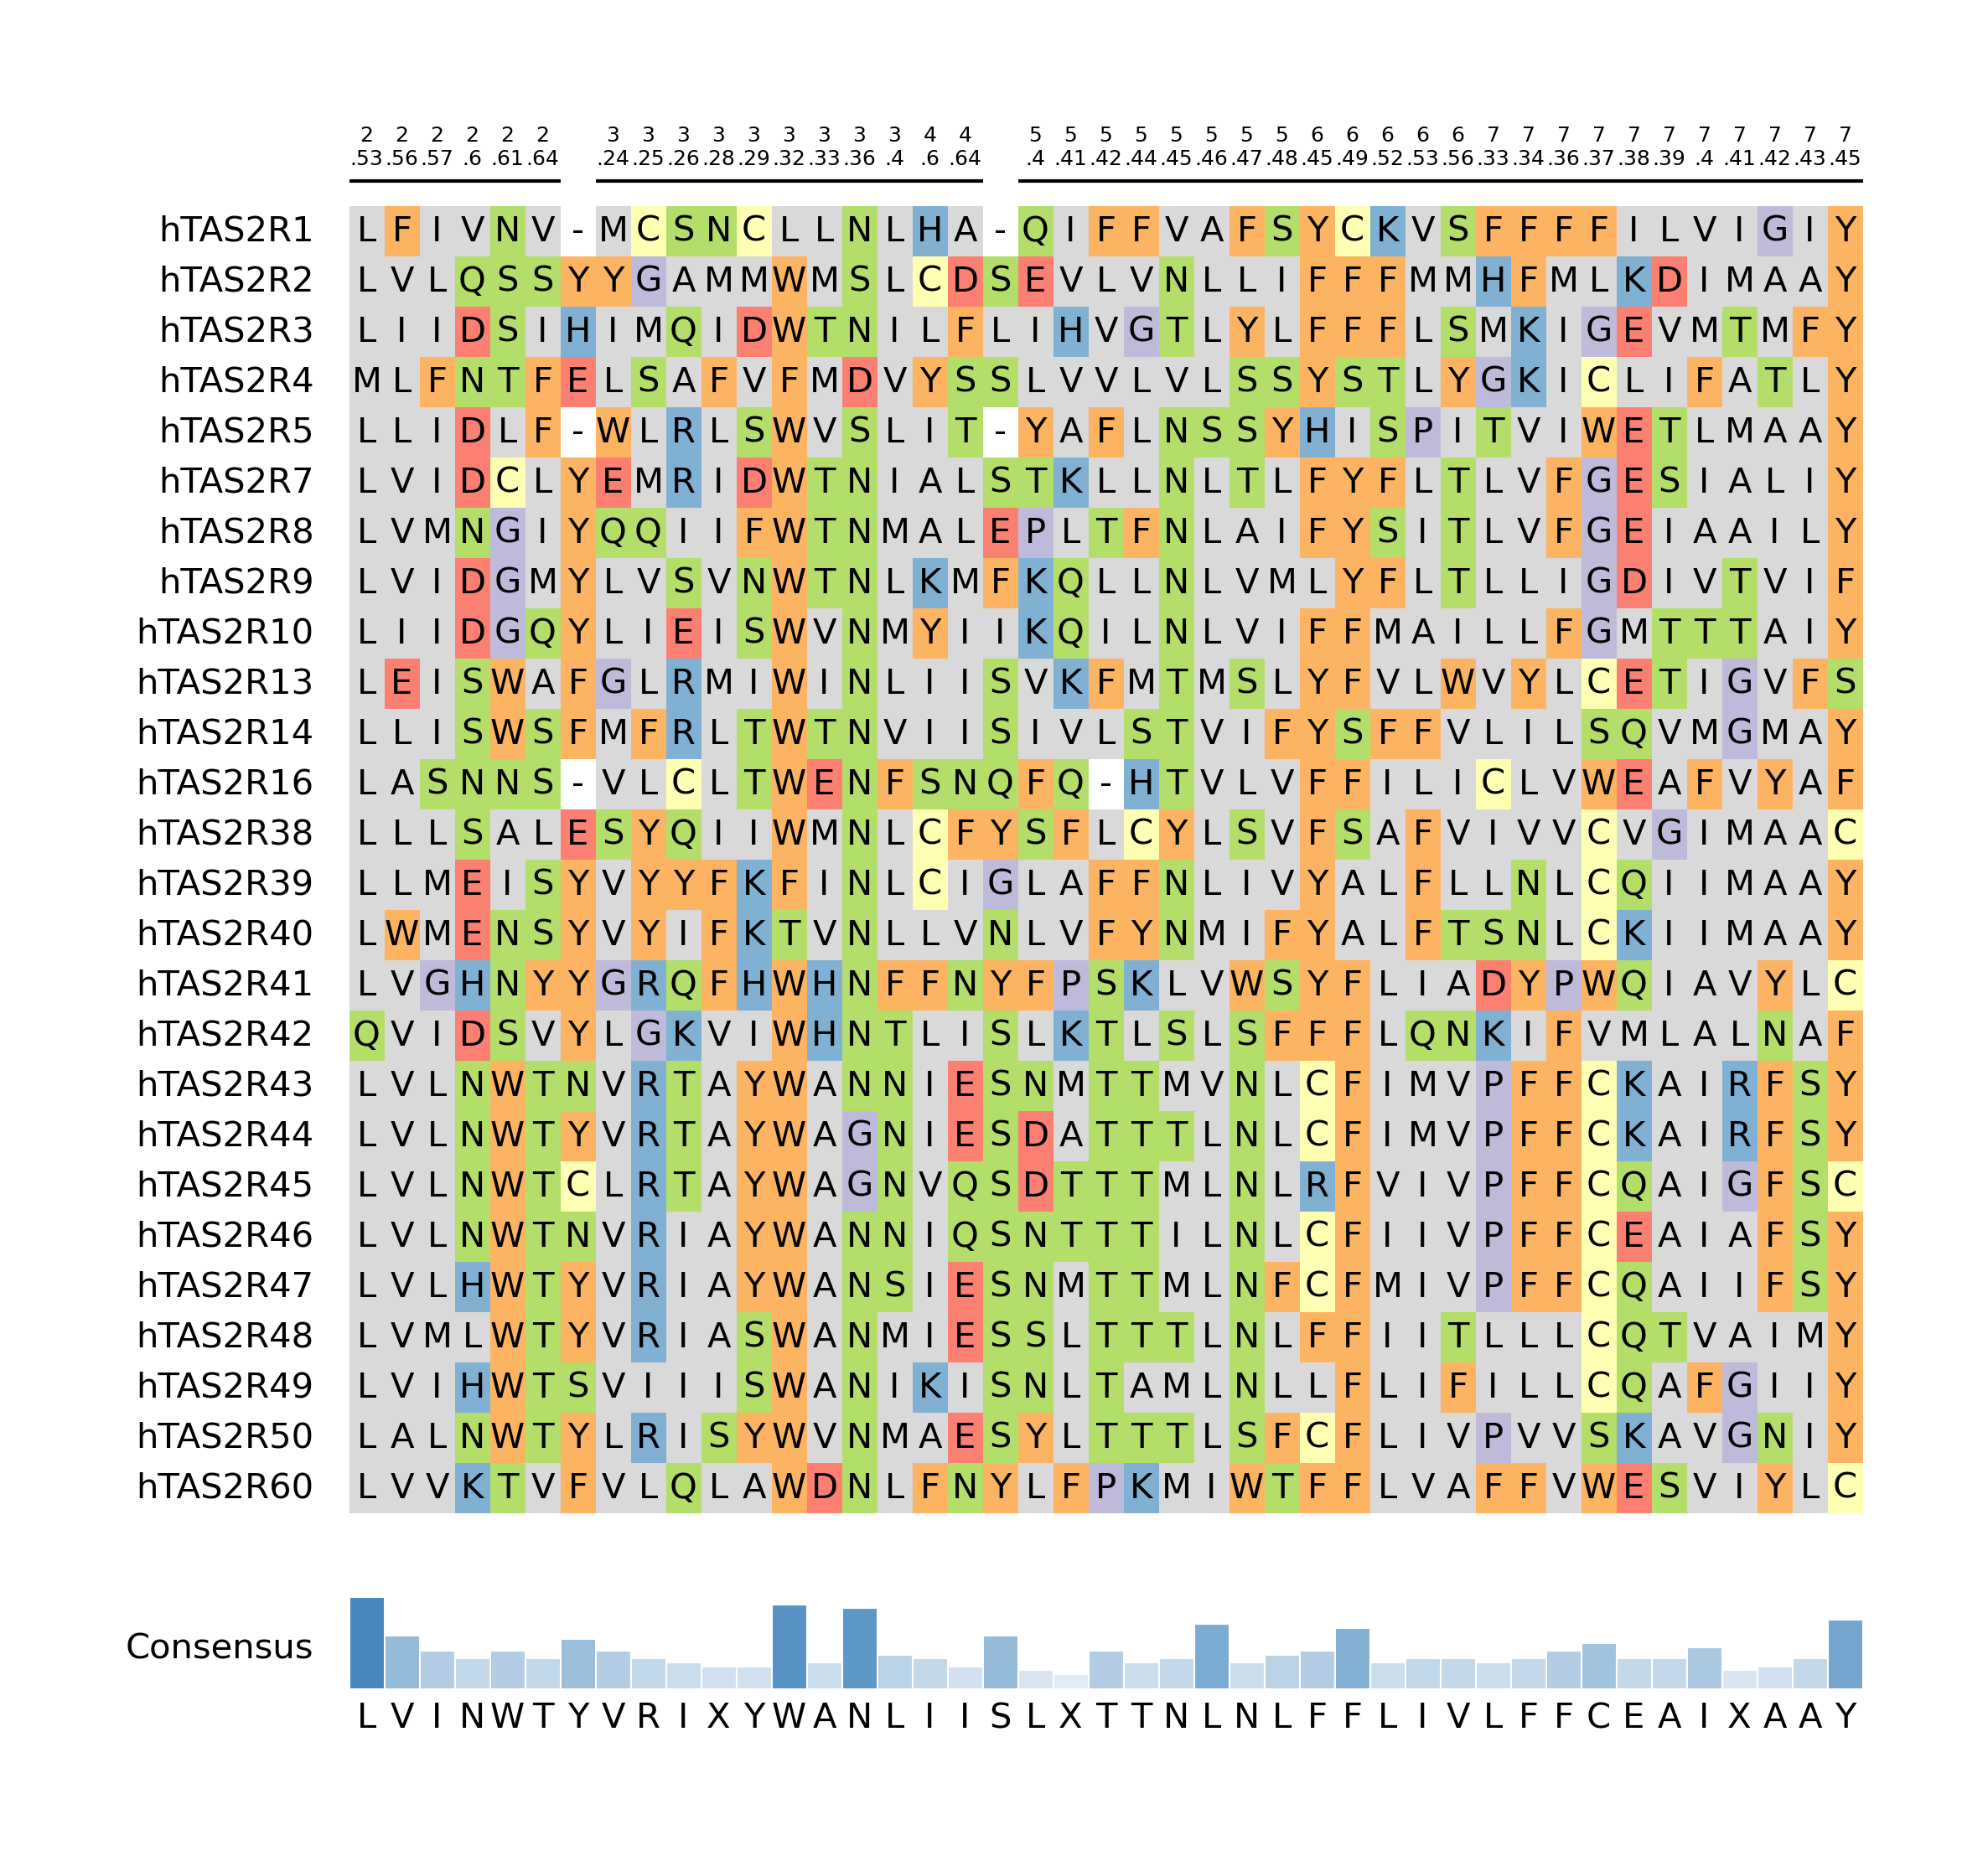

In [13]:
ecbs_msa = {}
for receptor in human_TAS2Rs:
    msa_sequence = msa.get_msa_sequence(receptor)
    selected_msa_sequence = ''.join([msa_sequence[msa_position] for msa_position in tas2r14_ecbs_msa_positions])
    ecbs_msa[receptor] = selected_msa_sequence

path_to_file = '../data/msa/hTAS2Rs_ecbs_msa.fa'
with open(path_to_file, 'w') as out:
    for receptor, sequence in ecbs_msa.items():
        out.write(f'>{receptor}\n')
        out.write(f'{sequence}\n')

mv = MsaViz(path_to_file, show_consensus=True, consensus_color='#377eb8')
mv.set_custom_color_scheme(custom_color_palette)
mv.set_plot_params(ticks_interval=None)
# bw numbers
for n, residue in enumerate(tas2r14_ecbs_residues, start=1):
    bw_number = BW_numbers.get_BW_number(residue, 'TAS2R14')
    
    if bw_number is None:
        continue
        
    mv.add_text_annotation((n, n), str(bw_number).replace('.', '\n.'), text_color="black", range_color="black", text_size=6)

fig = mv.plotfig(dpi=300)
fig.savefig('../figures/supplementary/Supplementary Figure 4A Aligned residues in the extracellular pocket of human TAS2Rs.png', dpi=300)

### Intracellular pocket

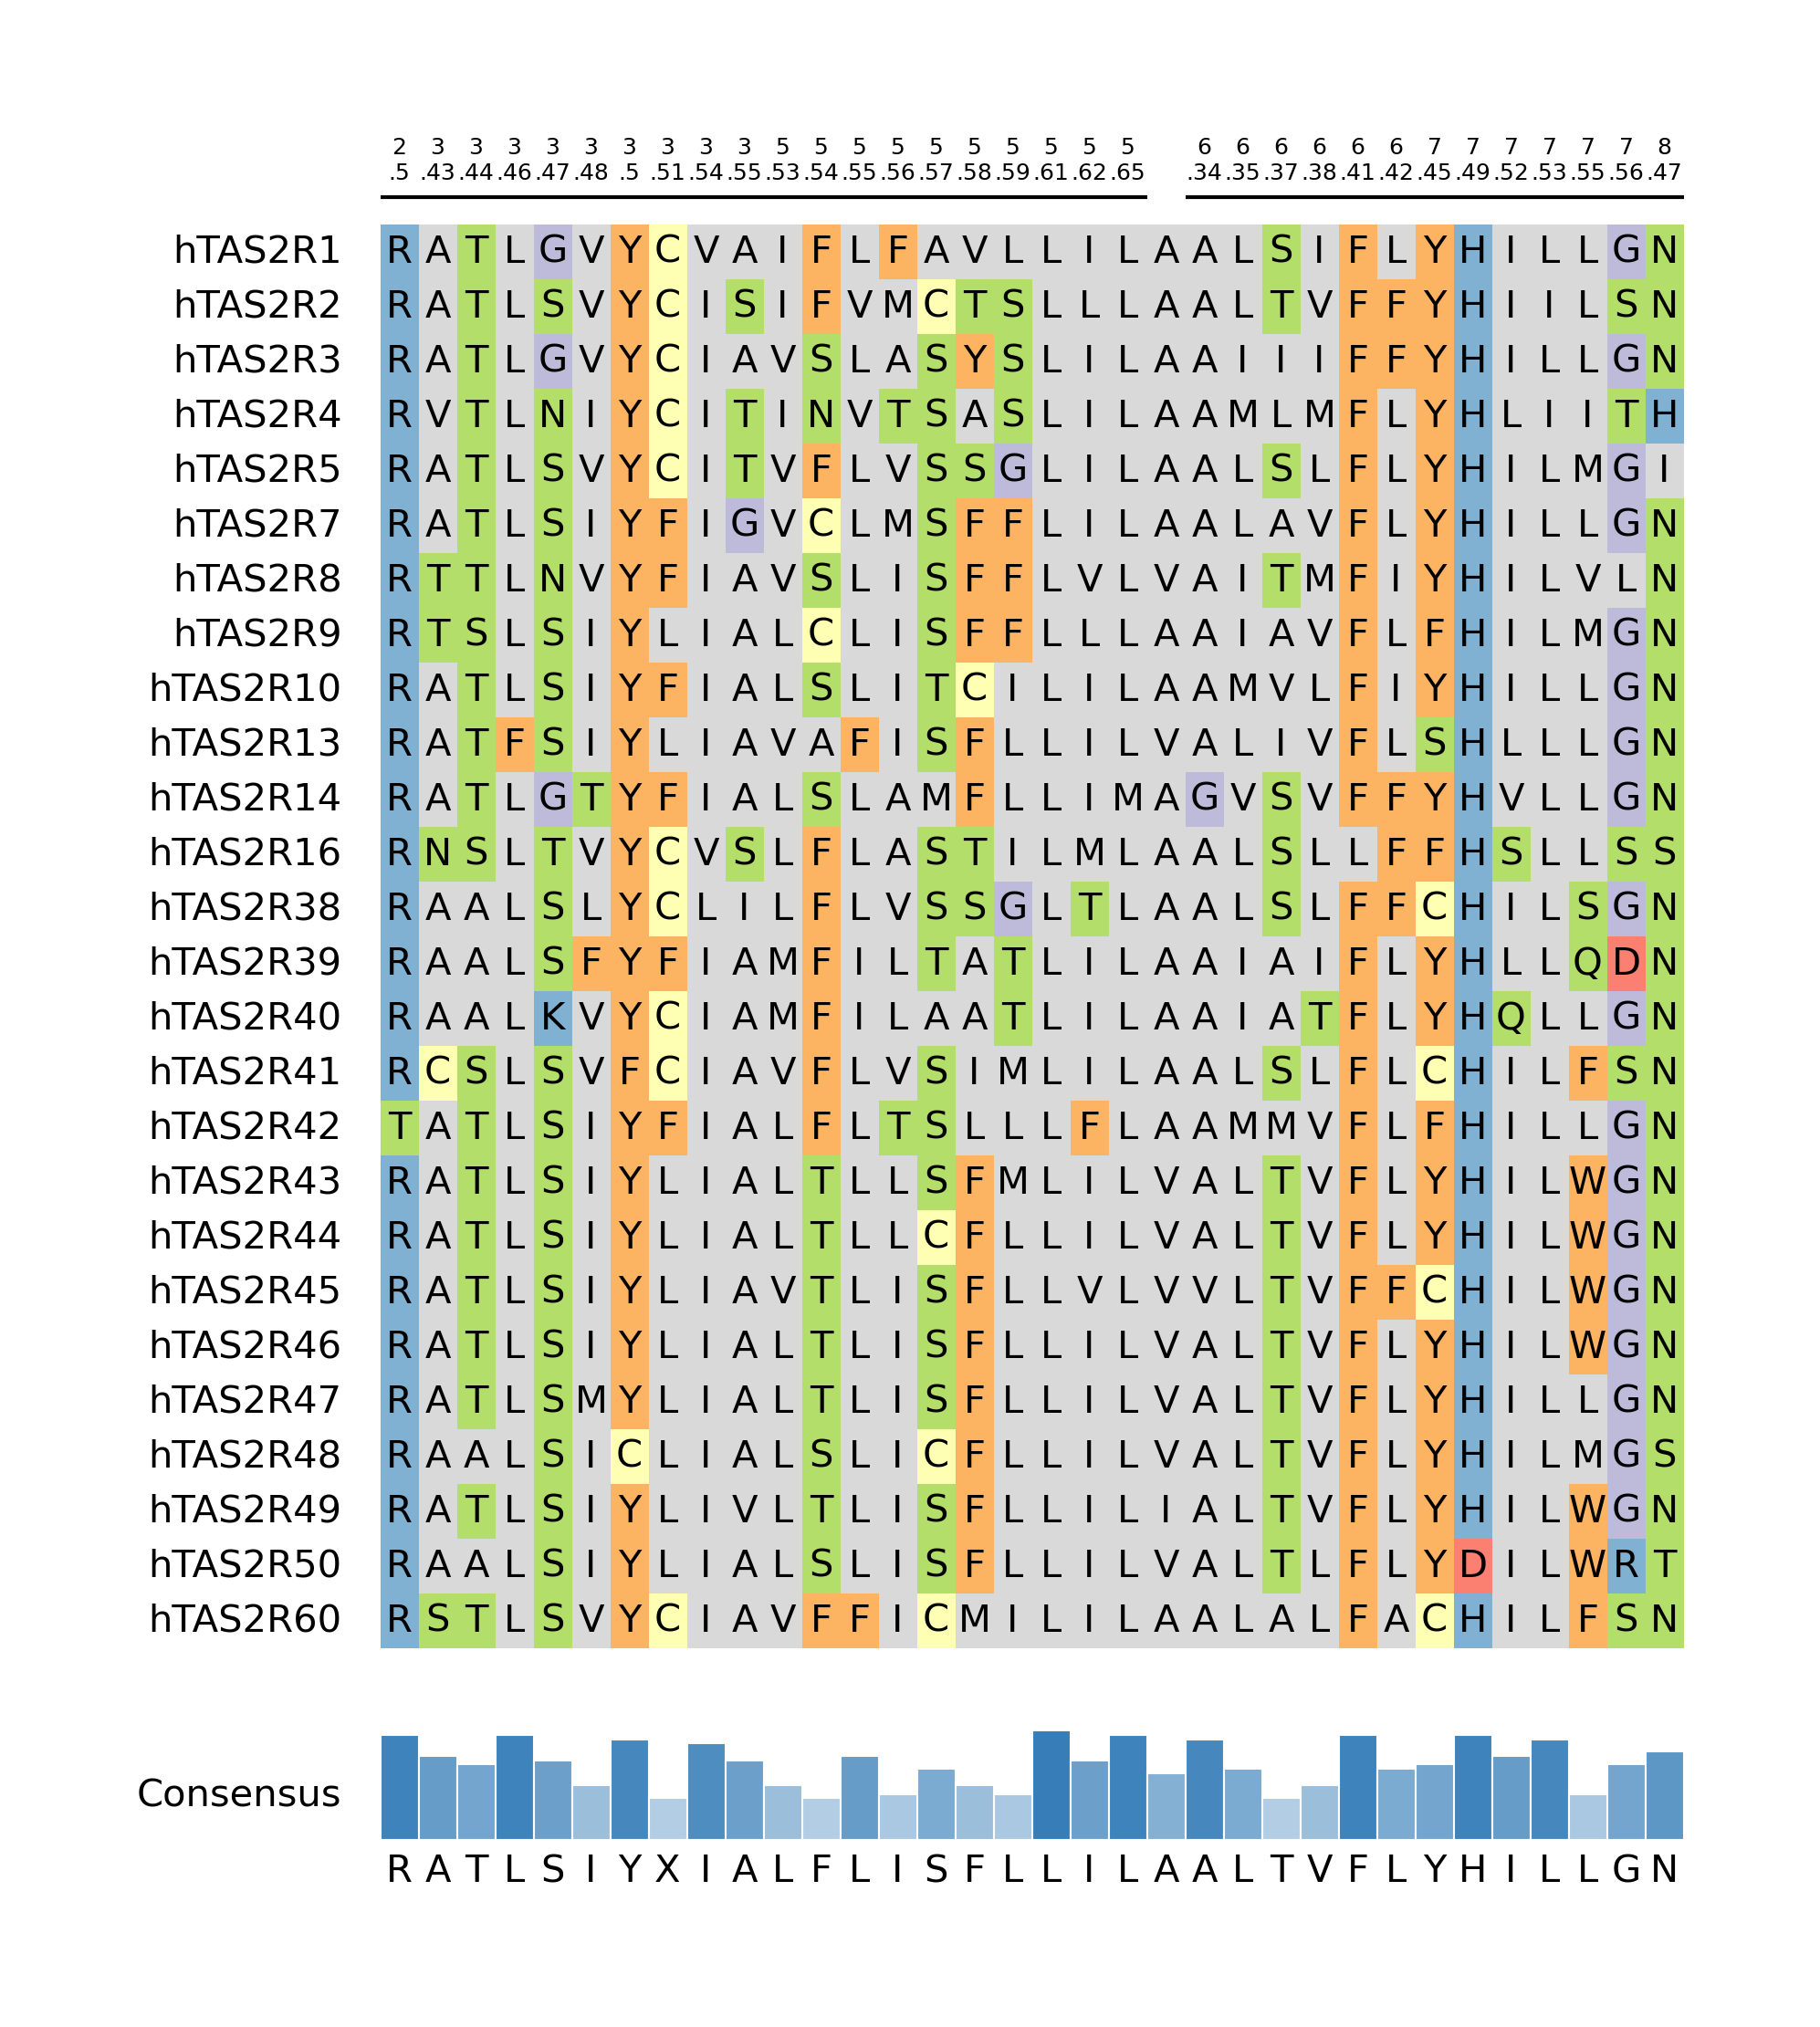

In [14]:
icbs_msa = {}
for receptor in human_TAS2Rs:
    msa_sequence = msa.get_msa_sequence(receptor)
    selected_msa_sequence = ''.join([msa_sequence[msa_position] for msa_position in tas2r14_icbs_msa_positions])
    icbs_msa[receptor] = selected_msa_sequence

path_to_file = '../data/msa/hTAS2Rs_icbs_msa.fa'
with open(path_to_file, 'w') as out:
    for receptor, sequence in icbs_msa.items():
        out.write(f'>{receptor}\n')
        out.write(f'{sequence}\n')

mv = MsaViz(path_to_file, show_consensus=True, consensus_color='#377eb8')
mv.set_custom_color_scheme(custom_color_palette)
mv.set_plot_params(ticks_interval=None)
# bw numbers
for n, residue in enumerate(tas2r14_icbs_residues, start=1):
    bw_number = BW_numbers.get_BW_number(residue, 'TAS2R14')
    
    if bw_number is None:
        continue
        
    mv.add_text_annotation((n, n), str(bw_number).replace('.', '\n.'), text_color="black", range_color="black", text_size=6)

fig = mv.plotfig(dpi=300)
fig.savefig('../figures/supplementary/Supplementary Figure 4B Aligned residues in the intracellular pocket of human TAS2Rs.png', dpi=300)

### Binding pocket replacement

In [15]:
receptor_pairs = pd.DataFrame([{'source receptor': 'TAS2R14', 'target receptor': 'TAS2R43'},
                               {'source receptor': 'TAS2R43', 'target receptor': 'TAS2R14'}])
binding_sites = ['intracellular', 'extracellular']

receptors_bs_transformation = []
for _, row in receptor_pairs.iterrows():
    
    source_receptor = row['source receptor']
    target_receptor = row['target receptor']
    
    for binding_site in binding_sites:

        source_bs_residues = TAS2Rs_bs_residues[(TAS2Rs_bs_residues['receptor'] == f'h{source_receptor}') & (TAS2Rs_bs_residues['binding site'] == binding_site)].iloc[0]['binding site residues']
        target_bs_residues = TAS2Rs_bs_residues[(TAS2Rs_bs_residues['receptor'] == f'h{target_receptor}') & (TAS2Rs_bs_residues['binding site'] == binding_site)].iloc[0]['binding site residues']

        source_sequence = msa.get_sequence(f'h{source_receptor}')
        source_msa_sequence = list(msa.get_msa_sequence(f'h{source_receptor}'))
        
        for residue in target_bs_residues:
            aa = residue[0]
            msa_position = msa.residue_to_msa_position(residue, f'h{target_receptor}')
            source_msa_sequence[msa_position] = aa

        transformed_sequence = ''.join(source_msa_sequence).replace('-', '')
        receptors_bs_transformation.append([source_receptor, target_receptor, binding_site, source_bs_residues, target_bs_residues, source_sequence, transformed_sequence])
receptors_bs_transformation = pd.DataFrame(receptors_bs_transformation, columns=['source receptor', 'target receptor', 'binding site', 'source bs residues', 'target bs residues', 'original sequence', 'transformed sequence'])

In [16]:
receptors_bs_transformation

,source receptor,target receptor,binding site,source bs residues,target bs residues,original sequence,transformed sequence
0,TAS2R14,TAS2R43,intracellular,"[R55, A100, T101, L103, G104, T105, Y107, F108...","[R55, A99, T100, L102, S103, I104, Y106, L107,...",MGGVIKSIFTFVLIVEFIIGNLGNSFIALVNCIDWVKGRKISSVDR...,MGGVIKSIFTFVLIVEFIIGNLGNSFIALVNCIDWVKGRKISSVDR...
1,TAS2R14,TAS2R43,extracellular,"[L58, L61, I62, S65, W66, S69, F76, M81, F82, ...","[L58, V61, L62, N65, W66, T69, N76, V80, R81, ...",MGGVIKSIFTFVLIVEFIIGNLGNSFIALVNCIDWVKGRKISSVDR...,MGGVIKSIFTFVLIVEFIIGNLGNSFIALVNCIDWVKGRKISSVDR...
2,TAS2R43,TAS2R14,intracellular,"[R55, A99, T100, L102, S103, I104, Y106, L107,...","[R55, A100, T101, L103, G104, T105, Y107, F108...",MITFLPIIFSSLVVVTFVIGNFANGFIALVNSIESFKRQKISFADQ...,MITFLPIIFSSLVVVTFVIGNFANGFIALVNSIESFKRQKISFADQ...
3,TAS2R43,TAS2R14,extracellular,"[L58, V61, L62, N65, W66, T69, N76, V80, R81, ...","[L58, L61, I62, S65, W66, S69, F76, M81, F82, ...",MITFLPIIFSSLVVVTFVIGNFANGFIALVNSIESFKRQKISFADQ...,MITFLPIIFSSLVVVTFVIGNFANGFIALVNSIESFKRQKISFADQ...


### Prepare configs for Boltz-2

In [17]:
# Load metadata on TAS2R cryo-EM complexes
path_to_meta_file = '../data/TAS2R_cryoEM_compexes/TAS2R_cryoEM_complexes_meta.xlsx'
aristolochic_acid_smiles = pd.read_excel(path_to_meta_file, sheet_name='ligands', index_col='ligand').loc['aristolochic acid']['smiles']

In [18]:
directory = 'Binding_pocket_replacement'
path_to_predictions = os.path.join('../predictions', directory)

path_to_config_directory = os.path.abspath(os.path.join('../configs/', directory))
if not os.path.exists(path_to_config_directory):
   os.makedirs(path_to_config_directory)

In [19]:
for _, row in receptors_bs_transformation.iterrows():
    
    # create config
    config_content = {'sequences': [{'protein': {'id': 'R', 'sequence': row['transformed sequence']}}, 
                                    {'ligand': {'id': 'L', 'smiles': aristolochic_acid_smiles}}],
                      'properties': [{'affinity': {'binder': 'L'}}]}
    # save config
    config_name = f"{row['target receptor']}_with_{row['source receptor']}_{row['binding site']}_BS.yaml"
    path_to_config = os.path.join(path_to_config_directory, config_name)
    with open(str(path_to_config), 'w') as out:
      yaml.safe_dump(config_content, out, sort_keys=False, allow_unicode=True)

### Run Boltz-2

In [20]:
# !boltz predict $path_to_config_directory --out_dir $path_to_predictions --diffusion_samples 10 --output_format pdb --use_msa_server

### Original TAS2R-AA results

In [70]:
aa_cofolding_results = []
path_to_cofolding_results = '../predictions/Cofolded_TAS2R_cryoEM_complexes/'
aa_directories = [file for file in os.listdir(path_to_cofolding_results) if file.startswith('aristolochic acid')]

for directory in sorted(aa_directories):

    ligand, receptor = directory.split('-')
    path_to_directory = os.path.join(path_to_cofolding_results, directory)

    affinity_file = f'affinity_{directory}.json'
    path_to_affinity_file = os.path.join(path_to_directory, affinity_file)
    
    if os.path.isfile(path_to_affinity_file):
        affinity_data = read_json(path_to_affinity_file)
    else:
        continue
    
    pdb_files = [file for file in os.listdir(path_to_directory) if file.endswith('.pdb')]

    for pdb_file in sorted(pdb_files):

        path_to_file = os.path.join(path_to_directory, pdb_file)
        interactions = get_ligands_interactions(path_to_file)
        interactions['Region'] = interactions['Residue'].apply(lambda residue: region_classyfier.get_residue_region(f'h{receptor}', residue))
        binding_site = interactions['Region'].value_counts().idxmax()

        confidence_file = f"confidence_{pdb_file.replace('.pdb', '.json')}"
        path_to_confidence_file = os.path.join(path_to_directory, confidence_file)
        confidence_data = read_json(path_to_confidence_file)
        aa_cofolding_results.append([path_to_file, pdb_file, ligand, receptor, interactions, binding_site, affinity_data, confidence_data])

aa_cofolding_results_df = pd.DataFrame(aa_cofolding_results, columns=['path to file', 'file name', 'ligand', 'source receptor', 'interactions', 'binding site', 'affinity data', 'confidence data'])
aa_cofolding_results_df['binding pocket'] = aa_cofolding_results_df['interactions'].apply(lambda interactions: interactions['Region'].value_counts().idxmax())
aa_cofolding_results_df['iptm'] = aa_cofolding_results_df['confidence data'].apply(lambda confidence_data: confidence_data['iptm'])
aa_cofolding_results_df['affinity predicted value'] = aa_cofolding_results_df['affinity data'].apply(lambda affinity_data: affinity_data['affinity_pred_value'])

aa_cofolding_results = []
for receptor, receptor_sub_df in aa_cofolding_results_df.groupby(by='source receptor'):
    binding_site_distr = receptor_sub_df['binding pocket'].value_counts().to_dict()
    ecbs_percent = binding_site_distr.setdefault('extracellular', 0) / len(receptor_sub_df) * 100
    icbs_percent = binding_site_distr.setdefault('intracellular', 0) / len(receptor_sub_df) * 100
    total = ecbs_percent + icbs_percent
    affinity = receptor_sub_df['affinity predicted value'].mean().round(2)
    mean_iptm = receptor_sub_df['iptm'].mean().round(2)
    aa_cofolding_results.append([receptor, ecbs_percent, icbs_percent, total, mean_iptm, affinity])
aa_cofolding_results_df = pd.DataFrame(aa_cofolding_results, columns=['source receptor', 'extracellular', 'intracellular', 'total', 'mean iptm', 'affinity'])
aa_cofolding_results_df = aa_cofolding_results_df.melt(id_vars=['source receptor','mean iptm', 'affinity', 'total'], value_vars=['extracellular', 'intracellular'], var_name='binding pocket', value_name='binding')
aa_cofolding_results_df['target receptor binding pocket'] = 'original'

In [71]:
aa_cofolding_results_df

,source receptor,mean iptm,affinity,total,binding pocket,binding,target receptor binding pocket
0,TAS2R14,0.88,0.75,100.0,extracellular,0.0,original
1,TAS2R43,0.88,0.73,100.0,extracellular,100.0,original
2,TAS2R14,0.88,0.75,100.0,intracellular,100.0,original
3,TAS2R43,0.88,0.73,100.0,intracellular,0.0,original


### Load co-folding results

In [72]:
cofolding_results = []
path_to_cofolding_results = '../predictions/Binding_pocket_replacement/'

prediction_directories = os.listdir(path_to_cofolding_results)

for directory in prediction_directories:

    source_receptor, target_receptor_binding_site = directory.split('_with_')
    target_receptor, binding_site, _ = target_receptor_binding_site.split('_')
    path_to_directory = os.path.join(path_to_cofolding_results, directory)

    affinity_file = f'affinity_{directory}.json'
    path_to_affinity_file = os.path.join(path_to_directory, affinity_file)
    affinity_data = read_json(path_to_affinity_file)
    
    pdb_files = [file for file in os.listdir(path_to_directory) if file.endswith('.pdb')]

    for pdb_file in sorted(pdb_files):
        path_to_file = os.path.join(path_to_directory, pdb_file)
        interactions = get_ligands_interactions(path_to_file)
        interactions['receptor region'] = interactions['Residue Number'].apply(lambda residue_number: classify_hTAS2R_residue_region(residue_number, source_receptor))
        
        confidence_file = f"confidence_{pdb_file.replace('.pdb', '.json')}"
        path_to_confidence_file = os.path.join(path_to_directory, confidence_file)
        confidence_data = read_json(path_to_confidence_file)
        
        cofolding_results.append([directory, source_receptor, target_receptor, binding_site, interactions, affinity_data, confidence_data])

cofolding_results_df = pd.DataFrame(cofolding_results, columns=['complex', 'source receptor', 'target receptor', 'target receptor binding pocket', 'interactions', 'affinity data', 'confidence data'])
cofolding_results_df['iptm'] = cofolding_results_df['confidence data'].apply(lambda confidence_data: confidence_data['iptm'])
cofolding_results_df['affinity predicted value'] = cofolding_results_df['affinity data'].apply(lambda affinity_data: affinity_data['affinity_pred_value'])
cofolding_results_df['binding pocket'] = cofolding_results_df['interactions'].apply(lambda interactions: interactions['receptor region'].value_counts().idxmax())

bp_replacement_results = []
for (source_receptor, target_receptor), receptor_sub_df in cofolding_results_df.groupby(by=['source receptor', 'target receptor']):
    for binding_site, binding_site_sub_df in receptor_sub_df.groupby(by='target receptor binding pocket'):
        binding_site_distr = binding_site_sub_df['binding pocket'].value_counts().to_dict()
        ecbs_percent = binding_site_distr.setdefault('extracellular', 0) / len(binding_site_sub_df) * 100
        icbs_percent = binding_site_distr.setdefault('intracellular', 0) / len(binding_site_sub_df) * 100
        total = ecbs_percent + icbs_percent
        affinity = binding_site_sub_df['affinity predicted value'].mean().round(2)
        mean_iptm = binding_site_sub_df['iptm'].mean().round(2)
        bp_replacement_results.append([source_receptor, target_receptor, binding_site, ecbs_percent, icbs_percent, total, mean_iptm, affinity])
bp_replacement_results = pd.DataFrame(bp_replacement_results, columns=['source receptor', 'target receptor', 'target receptor binding pocket', 'extracellular', 'intracellular', 'total', 'mean iptm', 'affinity'])
bp_replacement_results = bp_replacement_results.melt(id_vars=['source receptor', 'target receptor', 'target receptor binding pocket', 'mean iptm', 'affinity', 'total'], value_vars=['extracellular', 'intracellular'], var_name='binding pocket', value_name='binding')

In [73]:
bp_replacement_results = pd.concat([bp_replacement_results, aa_cofolding_results_df], ignore_index=True)
bp_replacement_results['target receptor binding pocket'] = pd.Categorical(bp_replacement_results['target receptor binding pocket'], categories=['original', 'extracellular', 'intracellular'], ordered=True)
bp_replacement_results

,source receptor,target receptor,target receptor binding pocket,mean iptm,affinity,total,binding pocket,binding
0,TAS2R14,TAS2R43,extracellular,0.90,1.05,100.0,extracellular,100.0
1,TAS2R14,TAS2R43,intracellular,0.86,0.90,100.0,extracellular,0.0
2,TAS2R43,TAS2R14,extracellular,0.66,1.08,100.0,extracellular,100.0
3,TAS2R43,TAS2R14,intracellular,0.82,0.76,100.0,extracellular,100.0
4,TAS2R14,TAS2R43,extracellular,0.90,1.05,100.0,intracellular,0.0
5,TAS2R14,TAS2R43,intracellular,0.86,0.90,100.0,intracellular,100.0
6,TAS2R43,TAS2R14,extracellular,0.66,1.08,100.0,intracellular,0.0
7,TAS2R43,TAS2R14,intracellular,0.82,0.76,100.0,intracellular,0.0
8,TAS2R14,NaN,original,0.88,0.75,100.0,extracellular,0.0
9,TAS2R43,NaN,original,0.88,0.73,100.0,extracellular,100.0


### TAS2R14

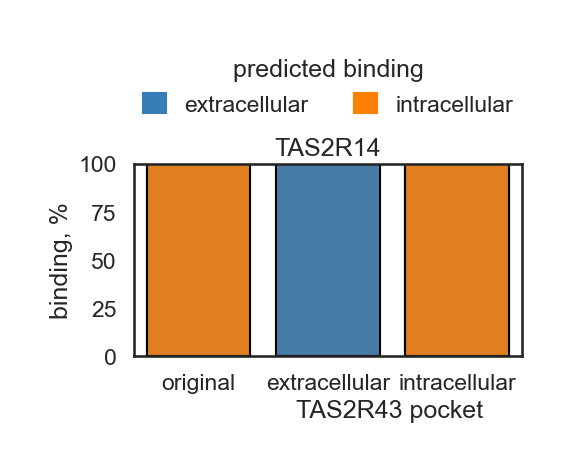

In [67]:
sns.set(rc={'figure.figsize':(5, 2.5)}, style='white', context='talk')

source_receptor = 'TAS2R14'
target_receptor = 'TAS2R43'

sub_df = bp_replacement_results[bp_replacement_results['source receptor'] == source_receptor].reset_index(drop=True)

intracellular = sub_df[sub_df['binding pocket'] == 'intracellular'].reset_index(drop=True)
bar_extracellular = sns.barplot(intracellular, x='target receptor binding pocket', y='total', color=palette[1], legend=False, edgecolor='black')
bar_intracellular = sns.barplot(intracellular, x='target receptor binding pocket', y='binding', color=palette[4], legend=False, edgecolor='black')
bar_intracellular.set(ylabel='binding, %', xlabel=f'{target_receptor} pocket', ylim=(0, 100), title=source_receptor)
bar_intracellular.xaxis.label.set_position((0.66, -0.1))

# add legend
top_bar = mpatches.Patch(color=palette[1], label='extracellular')
bottom_bar = mpatches.Patch(color=palette[4], label='intracellular')
bar_extracellular.legend(handles=[top_bar, bottom_bar], title='predicted binding')
sns.move_legend(bar_extracellular, 'center', bbox_to_anchor=(0.5, 1.4), ncol=2)

bar_extracellular.figure.savefig(f'../figures/main/Figure 2D {source_receptor} BP replacement.png', dpi=300, bbox_inches='tight')

### TAS2R43

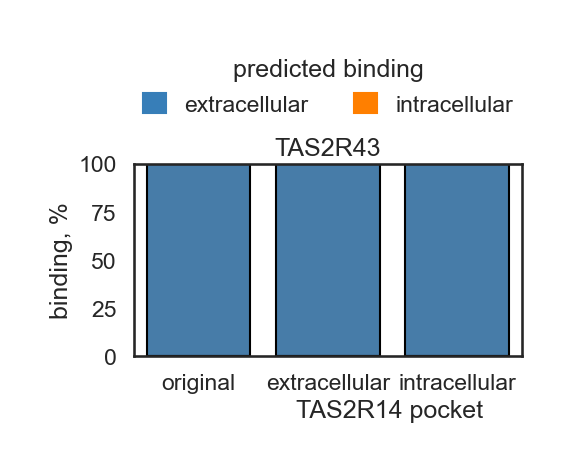

In [68]:
sns.set(rc={'figure.figsize':(5, 2.5)}, style='white', context='talk')

source_receptor = 'TAS2R43'
target_receptor = 'TAS2R14'

sub_df = bp_replacement_results[bp_replacement_results['source receptor'] == source_receptor].reset_index(drop=True)

intracellular = sub_df[sub_df['binding pocket'] == 'intracellular'].reset_index(drop=True)
bar_extracellular = sns.barplot(intracellular, x='target receptor binding pocket', y='total', color=palette[1], legend=False, edgecolor='black')
bar_intracellular = sns.barplot(intracellular, x='target receptor binding pocket', y='binding', color=palette[4], legend=False, edgecolor='black')
bar_intracellular.set(ylabel='binding, %', xlabel=f'{target_receptor} pocket', ylim=(0, 100), title=source_receptor)
bar_intracellular.xaxis.label.set_position((0.66, -0.1))

# add legend
top_bar = mpatches.Patch(color=palette[1], label='extracellular')
bottom_bar = mpatches.Patch(color=palette[4], label='intracellular')
bar_extracellular.legend(handles=[top_bar, bottom_bar], title='predicted binding')
sns.move_legend(bar_extracellular, 'center', bbox_to_anchor=(0.5, 1.4), ncol=2)

bar_extracellular.figure.savefig(f'../figures/main/Figure 2D {source_receptor} BP replacement.png', dpi=300, bbox_inches='tight')